## Figure 6: cell typing in space, Segger vs 10x (Atera cervical cancer)

Segger was seeded with the 10x cells, so both segmentations share cell ids and differ only in which transcripts each cell keeps.
That makes the comparison paired: the same cell, typed by the same CellTypist model, with 10x's transcripts or with Segger's.
A call is **ambiguous** when its CellTypist confidence is below 0.5 (confidence is close to 0 or 1 for almost every cell).

Panels (a, the transcript density of the Xenium and Atera datasets, is not made here):
- **b** UMAPs of 10x and Segger, with ambiguous calls as large dark grey dots.
- **c** The section, each paired cell coloured by its Segger cell type, with the fields of view of d.
- **d** Two 200 µm fields of view: (i) the epithelial–stromal interface and (ii) B cells meeting tumour epithelium.
- **e** Ambiguous calls per cell type.
- **f** Ambiguous calls against the diversity of a cell's neighbours.
- **g** Ambiguous calls against the share of a 10x cell's transcripts that Segger does not keep.
- **h** Transcripts per cell, own-lineage marker transcripts per cell and the foreign-lineage marker share.

Trends along a continuous variable are summarised in decile bins of cells: each bin's value is the percentage of its cells called ambiguous, drawn at the bin's mean x, with the interquartile range of that percentage across 500 µm squares of the tissue, since neighbouring cells are not independent.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import scanpy as sc
from scipy.spatial import cKDTree, ConvexHull
from matplotlib import pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.collections import PolyCollection
from matplotlib.patches import Rectangle
plt.style.use("btc_moormana")

# Local data paths (remove before sharing)
path_data = Path("/data1/collab002/sail/projects/ongoing/segger_dev/data")
path_bound_10x = path_data / "inputs/WTA_Preview_FFPE_Cervical_Cancer/cell_boundaries.parquet"
path_adata_10x = path_data / "inputs/WTA_Preview_FFPE_Cervical_Cancer/adata_umap.h5ad"
path_adata_seg = path_data / "outputs/WTA_Preview_FFPE_Cervical_Cancer/r040_bufratio_0.05_sgw1/adata_umap.h5ad"
path_cells_10x = path_data / "inputs/WTA_Preview_FFPE_Cervical_Cancer/cells.parquet"
path_tx = path_data / "inputs/WTA_Preview_FFPE_Cervical_Cancer/transcripts.parquet"
path_seg = path_data / "outputs/WTA_Preview_FFPE_Cervical_Cancer/r040_bufratio_0.05_sgw1/segger_segmentation.parquet"
path_ref = path_data / "inputs/scRNA_reference_FFPE_Cervical_Cancer/9k_Cervical_Cancer_scFFPE_count_filtered_feature_bc_matrix.h5ad"
path_celltypist = Path("/data1/collab002/sail/projects/ongoing/segger_dev/scripts/models/WTA_Preview_FFPE_Cervical_Cancer/celltypist_atera_10x.pkl")
path_cache = Path("../results/figure_6_atera")
path_cache.mkdir(parents=True, exist_ok=True)

METHODS = ["10x", "Segger"]
METHOD_COLORS = {"10x": "#163A5F", "Segger": "#0072B2"}  # sg_utils.pl.style, as in Supp. Fig. 10
AMBIGUOUS = 0.5  # CellTypist confidence below which a call is ambiguous
K_SPATIAL = 15  # spatial neighbours defining a cell's neighbourhood
BLOCK = 500  # µm, block size for bootstrap intervals

# Four lineages with mutually exclusive markers (see "Lineage markers" below)
LINEAGE = {
    "Basal": "Epithelial", "Parabasal": "Epithelial", "Differentiating": "Epithelial", "Hypoxic": "Epithelial",
    "Glandular": "Epithelial", "T cell": "Lymphoid", "B cell": "Lymphoid", "Plasma": "Lymphoid",
    "Macrophage": "Myeloid", "Dendritic": "Myeloid", "Neutrophil": "Myeloid", "Mast": "Myeloid",
    "Fibroblast": "Stromal", "Smooth muscle": "Stromal", "Endothelial": "Stromal",
}
LINEAGES = sorted(set(LINEAGE.values()))
# Cell-type colours of Supp. Fig. 10 (Parabasal has no counterpart there)
TYPE_COLORS = {
    "Basal": "#a64b0b", "Parabasal": "#d9661a", "Differentiating": "#f58a1f", "Hypoxic": "#fbc46b",
    "Glandular": "#1f7a70", "T cell": "#7b3fa8", "B cell": "#2fcb57", "Plasma": "#74d890",
    "Macrophage": "#b5179e", "Dendritic": "#e86fd0", "Neutrophil": "#ff9ec4", "Mast": "#6b0f45",
    "Fibroblast": "#6ba8d6", "Smooth muscle": "#1f5fa8", "Endothelial": "#e03127", "Unresolved": "#55555e",
}
FOV_BACKGROUND = "#141416"  # as in Supp. Fig. 10


def dim(color, amount=0.7):
    """Blend `color` towards the FOV background, so highlighted cells stand out against it."""
    rgb, background = np.array(mcolors.to_rgb(color)), np.array(mcolors.to_rgb(FOV_BACKGROUND))
    return mcolors.to_hex(amount * rgb + (1 - amount) * background)


AMBIGUOUS_COLOR = "darkgray"  # #a9a9a9; ambiguous calls in the FOVs and the low-confidence end in the UMAPs

# Benchmark panels in the style of sg_utils.pl.style.set_style and sg_utils.pl.benchmark.bars
MM = 1 / 25.4
INK, MUTED = "#1A1A1A", "#8A8F98"
BENCH_STYLE = {
    "font.size": 6.5, "axes.titlesize": 7, "axes.labelsize": 6.5, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6, "axes.linewidth": 0.6, "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.0, "ytick.major.size": 2.0, "axes.spines.top": False, "axes.spines.right": False,
}
REMOVED_COLOR = "#d62728"

### Paired cells

Only the 670,995 cells in both segmentations are compared (Segger drops 10x cells that keep too few transcripts).
The UMAP of each segmentation (panel b) keeps all its cells.

In [2]:
adatas = {"10x": sc.read_h5ad(path_adata_10x), "Segger": sc.read_h5ad(path_adata_seg)}
shared = adatas["10x"].obs_names.intersection(adatas["Segger"].obs_names)
print(", ".join(f"{m}: {a.n_obs:,} cells" for m, a in adatas.items()) + f"; {len(shared):,} shared")
umaps = {
    m: pd.DataFrame({
        "umap1": a.obsm["X_umap"][:, 0], "umap2": a.obsm["X_umap"][:, 1],
        "type": a.obs["celltype"].astype(str).to_numpy(), "confidence": a.obs["confidence"].to_numpy(),
    }, index=a.obs_names)
    for m, a in adatas.items()
}
adatas = {m: a[shared].copy() for m, a in adatas.items()}

xy = (
    pl.read_parquet(path_cells_10x, columns=["cell_id", "x_centroid", "y_centroid"])
    .to_pandas().set_index("cell_id").loc[shared].to_numpy()
)
cells = pd.DataFrame({"x": xy[:, 0], "y": xy[:, 1]}, index=shared)
cells["block"] = (xy[:, 0] // BLOCK).astype(int) * 1000 + (xy[:, 1] // BLOCK).astype(int)
for m, a in adatas.items():
    cells[f"type_{m}"] = a.obs["celltype"].astype(str).to_numpy()
    cells[f"lineage_{m}"] = cells[f"type_{m}"].map(LINEAGE)
    cells[f"conf_{m}"] = a.obs["confidence"].to_numpy()
    cells[f"ambiguous_{m}"] = cells[f"conf_{m}"] < AMBIGUOUS
    cells[f"n_{m}"] = a.obs["n_counts"].to_numpy()
pd.DataFrame({m: {"ambiguous (%)": 100 * cells[f"ambiguous_{m}"].mean()} for m in METHODS})

10x: 714,210 cells, Segger: 670,998 cells; 670,995 shared


,10x,Segger
ambiguous (%),20.071387,8.174726


### Lineage markers from the matched single-cell reference

Cell types are grouped into four lineages whose markers are mutually exclusive in biology: epithelial, lymphoid (T, B and plasma cells), myeloid, and stromal (fibroblasts, mural and endothelial cells).
T and B/plasma cells (mean profiles r = 0.55 in the reference) and endothelial and fibroblast/mural cells (r = 0.53) share most of their candidate markers, so they are merged; all other pairs correlate at r ≤ 0.41.
The reference is 10x's matched scFFPE (Chromium Flex) data of cervical cancer, 9,503 dissociated cells, so its marker specificity does not depend on any segmentation.
It has no labels; its cells are labelled with the CellTypist model that typed the section, and confident labels (≥ 0.5) are grouped into lineages.

Epithelial reference cells have about 2,000 UMIs, the other lineages 300–600, so a gene that is merely undetected at low depth would look epithelial-specific.
Every reference cell is therefore downsampled to 300 UMIs (cells with fewer are dropped) before markers are called.
**Lineage markers**: one-versus-rest Wilcoxon test on the log-normalised, depth-matched reference, adjusted P < 0.01; detected in at least 10% of the lineage's cells; and, against **each** other lineage separately, mean expression at least eightfold higher and detection below 50%.
Exclusivity is judged by fold enrichment rather than a strict detection cut, because ambient RNA in the dissociated reference puts abundant genes at low level into many cells of every lineage (KRT13 is detected in 20% of lymphoid reference cells but is 18-fold enriched in epithelium); the 50% cap guards against genes another lineage truly expresses.
There is no cap on the number of markers.

**Foreign share** of a cell: its transcripts of other lineages' markers, out of all its lineage-marker transcripts.
Each segmentation is scored by its own annotation (CellTypist's top label, also for ambiguous calls); the reference cells (at full depth) by their labels.
The reference value is the foreign share of cells that were never segmented: what imperfect marker exclusivity, ambient RNA and true low-level expression contribute.
The excess over it estimates what segmentation contributes.

In [3]:
import sys
import celltypist

REF_DEPTH = 300  # UMIs per reference cell when calling markers
MAX_P, MIN_IN, MAX_OUT, MIN_FOLD = 0.01, 0.10, 0.50, 8


def load_celltypist(path):
    """Load a CellTypist model pickled under numpy 2 into numpy 1 (numpy._core aliased while unpickling)."""
    alias = {"numpy._core": np.core, "numpy._core.numeric": np.core.numeric, "numpy._core.multiarray": np.core.multiarray}
    sys.modules.update(alias)
    try:
        return celltypist.models.Model.load(str(path))
    finally:
        for name in alias:
            sys.modules.pop(name, None)


ref = sc.read_h5ad(path_ref)
ref.var_names_make_unique()
query = ref.copy()
sc.pp.normalize_total(query, target_sum=1e4)
sc.pp.log1p(query)
typed = celltypist.annotate(query, model=load_celltypist(path_celltypist), majority_voting=False)
ref.obs["lineage"] = typed.predicted_labels["predicted_labels"].astype(str).map(LINEAGE).to_numpy()
ref = ref[(typed.probability_matrix.max(axis=1).to_numpy() >= 0.5) & ref.obs["lineage"].notna().to_numpy()].copy()
lineages = sorted(ref.obs["lineage"].unique())
print("reference UMIs per cell (median):",
      ref.obs.assign(n=np.asarray(ref.X.sum(1)).ravel()).groupby("lineage")["n"].median().to_dict())

genes = sorted(set(ref.var_names) & set(adatas["10x"].var_names) & set(adatas["Segger"].var_names))
matched = ref[np.asarray(ref.X.sum(1)).ravel() >= REF_DEPTH, genes].copy()
sc.pp.downsample_counts(matched, counts_per_cell=REF_DEPTH, random_state=0)
sc.pp.normalize_total(matched, target_sum=1e4)
sc.pp.log1p(matched)
matched.obs["lineage"] = pd.Categorical(matched.obs["lineage"])
sc.tl.rank_genes_groups(matched, "lineage", method="wilcoxon", use_raw=False)
labels_matched = matched.obs["lineage"].astype(str).to_numpy()
detection = pd.DataFrame(
    {L: np.asarray((matched.X[labels_matched == L] > 0).mean(0)).ravel() for L in lineages}, index=genes)
mean_cp10k = pd.DataFrame(
    {L: np.asarray(np.expm1(matched.X[labels_matched == L]).mean(0)).ravel() for L in lineages}, index=genes)

def select_markers(min_fold):
    """Exclusive markers of every lineage at a fold-enrichment threshold over each other lineage."""
    markers = {}
    for L in lineages:
        df = sc.get.rank_genes_groups_df(matched, group=L).set_index("names")
        candidates = df.index[df["pvals_adj"] < MAX_P]
        others = [M for M in lineages if M != L]
        fold = (mean_cp10k.loc[candidates, L] + 1e-3) / (mean_cp10k.loc[candidates, others].max(axis=1) + 1e-3)
        exclusive = (
            (detection.loc[candidates, L] >= MIN_IN)
            & (detection.loc[candidates, others].max(axis=1) < MAX_OUT)
            & (fold > min_fold)
        )
        markers[L] = sorted(candidates[exclusive.to_numpy()])
    return markers


lineage_markers = select_markers(MIN_FOLD)


def lineage_counts(adata, markers=None):
    """Transcripts of each lineage's markers per cell (cells x lineages)."""
    markers = markers or lineage_markers
    X = adata.X.tocsr()
    column = {g: j for j, g in enumerate(adata.var_names)}
    return np.stack([np.asarray(X[:, [column[g] for g in markers[L]]].sum(1)).ravel() for L in lineages], 1)


def own_foreign(counts, labels):
    """Own- and foreign-lineage marker transcripts per cell, given each cell's lineage (NaN when unknown)."""
    known = pd.notna(labels)
    idx = np.array([lineages.index(L) if k else 0 for L, k in zip(labels, known)])
    own = counts[np.arange(len(idx)), idx]
    return np.where(known, own, np.nan), np.where(known, counts.sum(1) - own, np.nan)


marker_counts = {m: lineage_counts(adatas[m]) for m in METHODS}
for m in METHODS:
    own, foreign = own_foreign(marker_counts[m], cells[f"lineage_{m}"].to_numpy())
    cells[f"own_markers_{m}"], cells[f"foreign_markers_{m}"] = own, foreign
ref_own, ref_foreign = own_foreign(lineage_counts(ref[:, genes]), ref.obs["lineage"].to_numpy())

pd.DataFrame({"n": {L: len(g) for L, g in lineage_markers.items()},
              "markers": {L: ", ".join(g[:12]) + (" …" if len(g) > 12 else "") for L, g in lineage_markers.items()}})

/data1/peerd/btc_moormana/GitHub/segger-reproducibility/.pixi/envs/cuda121/lib/python3.11/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


🔬 Input data has 9503 cells and 18082 genes


🔗 Matching reference genes in the model


🧬 1593 features used for prediction


⚖️ Scaling input data


🖋️ Predicting labels


✅ Prediction done!


reference UMIs per cell (median): {'Epithelial': 2020.0, 'Lymphoid': 335.5, 'Myeloid': 633.0, 'Stromal': 382.0}


,n,markers
Epithelial,75,"ATP1B1, CALML3, CD24, CDKN2A, CDKN2B, CHMP4B, ..."
Lymphoid,25,"BCL11B, CCL5, CD2, CD3E, CD6, CD8A, CD96, DUSP..."
Myeloid,56,"ADAMTSL4, ALOX5, APOE, C1QA, C1QB, C1QC, CD14,..."
Stromal,57,"ADAM33, ADAMTS1, ADAMTS2, ADAMTS4, ADAMTS9, AE..."


### Contamination removed by Segger

One pass over the 1.04 billion transcripts (about 1 min, cached) counts, for every 10x cell, the transcripts Segger keeps in that cell, gives to another cell, or leaves unassigned (similarity below its gene's threshold).
**Removed** is the share of a 10x cell's transcripts that Segger does not keep in it.

In [4]:
path_reassign = path_cache / "reassignment.parquet"
if not path_reassign.exists():
    tx = (
        pl.scan_parquet(path_tx).with_row_index("row_index")
        .select(pl.col("row_index").cast(pl.Int64), "cell_id")
        .filter(pl.col("cell_id") != "UNASSIGNED")
    )
    seg = pl.scan_parquet(path_seg).select("row_index", pl.when("filtered").then("segger_cell_id").alias("seg"))
    (
        tx.join(seg, on="row_index").group_by("cell_id").agg(
            pl.len().alias("n"),
            (pl.col("seg") == pl.col("cell_id")).sum().alias("n_kept"),
            ((pl.col("seg") != pl.col("cell_id")) & pl.col("seg").is_not_null()).sum().alias("n_other_cell"),
        )
        .collect(engine="streaming").write_parquet(path_reassign)
    )
reassign = pl.read_parquet(path_reassign).to_pandas().set_index("cell_id").reindex(cells.index)
cells["removed"] = 1 - reassign["n_kept"] / reassign["n"]
cells["to_other_cell"] = reassign["n_other_cell"] / reassign["n"]
cells[["removed", "to_other_cell"]].describe()

,removed,to_other_cell
count,670995.000000,670995.000000
mean,0.185793,0.024659
std,0.185331,0.026487
min,0.000000,0.000000
25%,0.054545,0.005319
50%,0.114548,0.017291
75%,0.254545,0.035461
max,0.984165,0.506494


### Neighbour-label entropy

A cell's **consensus** label is its cell type when both methods call it confidently and agree.
**Neighbour-label entropy** is the Shannon entropy (bits) of the consensus labels of the 15 nearest cells (10x centroids; at least 5 labelled neighbours).
It does not depend on the cell's own call and is the same for both methods.


In [5]:
consensus = cells["type_10x"].where(
    (cells["type_10x"] == cells["type_Segger"]) & ~cells["ambiguous_10x"] & ~cells["ambiguous_Segger"]
)
_, nn = cKDTree(xy).query(xy, k=K_SPATIAL + 1)
codes, labels = pd.factorize(consensus)  # -1 where there is no consensus
neighbours = codes[nn[:, 1:]]
counts = np.stack([(neighbours == k).sum(1) for k in range(len(labels))], 1)
n_labelled = counts.sum(1, keepdims=True)
p = counts / np.maximum(n_labelled, 1)
entropy = -np.sum(p * np.log2(np.where(p > 0, p, 1)), 1)
cells["entropy"] = np.where(n_labelled[:, 0] >= 5, entropy, np.nan)

def block_bootstrap(cells, value, by, n_boot=1000, seed=0):
    """Mean of `value` per bin of `by`, with 95% intervals from resampling spatial blocks."""
    data = cells[[value, by, "block"]].dropna()
    data = data.assign(**{value: data[value].astype(float)})
    sums = data.pivot_table(value, "block", by, aggfunc="sum", fill_value=0, observed=True)
    sizes = data.pivot_table(value, "block", by, aggfunc="size", fill_value=0, observed=True)
    weights = np.random.default_rng(seed).multinomial(len(sums), np.full(len(sums), 1 / len(sums)), n_boot)
    boot = (weights @ sums.to_numpy()) / (weights @ sizes.to_numpy())
    return pd.DataFrame({
        "mean": sums.sum() / sizes.sum(),
        "low": np.percentile(boot, 2.5, 0),
        "high": np.percentile(boot, 97.5, 0),
        "n": sizes.sum(),
    }, index=sums.columns)


MIN_BLOCK_CELLS = 30  # cells of a decile a block needs to enter its spread across squares


def decile_curves(cells, x, values):
    """Bin cells into deciles of `x`; per decile, the pooled mean of each value with its block-bootstrap
    interval, the decile's mean `x`, and quantiles of the value over 500 µm blocks.
    """
    binned = cells.assign(bin=pd.qcut(cells[x], 10, labels=False, duplicates="drop"))
    centres = binned.groupby("bin")[x].mean()
    curves = {}
    for v in values:
        per_block = (
            binned.dropna(subset=[v]).assign(**{v: lambda d: d[v].astype(float)})
            .groupby(["bin", "block"])[v].agg(["mean", "size"])
        )
        per_block = per_block.loc[per_block["size"] >= MIN_BLOCK_CELLS, "mean"].groupby(level="bin")
        spread = per_block.quantile([0.25, 0.75]).unstack()
        spread.columns = ["q25", "q75"]
        curves[v] = block_bootstrap(binned, v, "bin").assign(x=centres, n_blocks=per_block.size()).join(spread)
    return curves


curves_entropy = decile_curves(cells, "entropy", [f"ambiguous_{m}" for m in METHODS])
curves_removed = decile_curves(cells, "removed", [f"ambiguous_{m}" for m in METHODS])
pd.concat(
    {f"{k} vs entropy": c["mean"] for k, c in curves_entropy.items()}
    | {f"{k} vs removed": c["mean"] for k, c in curves_removed.items()},
    axis=1,
).round(3)


,ambiguous_10x vs entropy,ambiguous_Segger vs entropy,ambiguous_10x vs removed,ambiguous_Segger vs removed
bin,,,,
0.0,0.091,0.054,0.128,0.105
1.0,0.155,0.079,0.132,0.097
2.0,0.181,0.088,0.136,0.092
3.0,0.198,0.089,0.143,0.087
4.0,0.221,0.095,0.163,0.089
5.0,0.254,0.099,0.192,0.087
6.0,0.257,0.087,0.217,0.080
7.0,0.274,0.085,0.246,0.069
8.0,0.277,0.080,0.293,0.060


### Fields of view

The two 200 µm fields of view of panel d, (i) the epithelial–stromal interface and (ii) B cells meeting tumour epithelium, by their top-left corner in µm.


In [6]:
FOV_SIZE = 200
EXAMPLES = {"i": (6500, 6450), "ii": (5400, 7100)}  # (x0, y0) of the fields of view
fovs = pd.DataFrame(EXAMPLES.values(), index=list(EXAMPLES), columns=["x0", "y0"])
fovs

,x0,y0
i,6500,6450
ii,5400,7100


### Reading windows of the section

`load_window` reads the 10x boundaries and every transcript in a square window, with both assignments: `cell_10x` and `cell_Segger` (Segger cells drawn as the convex hull of the transcripts they keep).

In [7]:
MARGIN = 15


def in_box(x0, y0, size, xc, yc, margin=MARGIN):
    return (
        pl.col(xc).is_between(x0 - margin, x0 + size + margin)
        & pl.col(yc).is_between(y0 - margin, y0 + size + margin)
    )


def load_window(x0, y0, size):
    bounds = pl.scan_parquet(path_bound_10x).filter(in_box(x0, y0, size, "vertex_x", "vertex_y")).collect()
    polys_10x = {cid: g.select("vertex_x", "vertex_y").to_numpy() for (cid,), g in bounds.group_by("cell_id")}
    seg = (
        pl.scan_parquet(path_seg).filter(in_box(x0, y0, size, "x", "y"))
        .select("row_index", "segger_cell_id", "filtered", "x", "y", "feature_name").collect()
    )
    tx = (
        pl.scan_parquet(path_tx).with_row_index("row_index")
        .filter(in_box(x0, y0, size, "x_location", "y_location"))
        .select(pl.col("row_index").cast(pl.Int64), "cell_id").collect()
    )
    tx = seg.join(tx, on="row_index").with_columns(
        pl.when(pl.col("filtered")).then("segger_cell_id").alias("cell_Segger"),
        pl.when(pl.col("cell_id") != "UNASSIGNED").then("cell_id").alias("cell_10x"),
    ).drop("segger_cell_id", "cell_id", "filtered")
    polys_seg = {}
    for (cid,), g in tx.filter(pl.col("cell_Segger").is_not_null()).group_by("cell_Segger"):
        pts = g.select("x", "y").to_numpy()
        if len(pts) >= 3:
            polys_seg[cid] = pts[ConvexHull(pts).vertices]
    return {"10x": polys_10x, "Segger": polys_seg}, tx


def dark_tile(ax, x0, y0, size):
    """Square field of view in µm on the FOV background, y increasing downwards.

    The background is a patch rather than the axes face colour, which `savefig.transparent` would drop.
    """
    ax.add_patch(Rectangle((x0, y0), size, size, color=FOV_BACKGROUND, zorder=-1))
    ax.set_xlim(x0, x0 + size)
    ax.set_ylim(y0 + size, y0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


def dark_legend(fig, handles, **kwargs):
    return fig.legend(handles=handles, frameon=True, facecolor=FOV_BACKGROUND, edgecolor=FOV_BACKGROUND,
                      framealpha=1, labelcolor="white", fontsize=5, **kwargs)


fov_data = {k: load_window(fov.x0, fov.y0, FOV_SIZE) for k, fov in fovs.iterrows()}

### b. UMAPs

All cells of each segmentation on its own UMAP, coloured by cell type, with ambiguous calls (CellTypist confidence below 0.5) in dark grey and 1.5 times larger. Cells are drawn in random order.

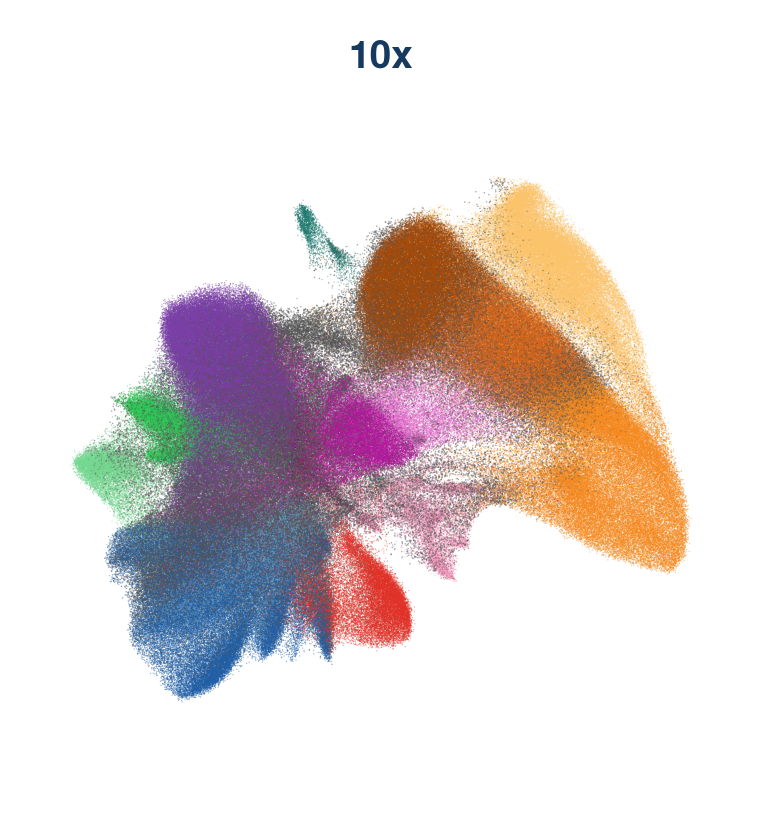

In [8]:
UMAP_POINT_SIZE = 0.05  # ambiguous cells are drawn 1.5x larger
UMAP_AMBIGUOUS_COLOR = "#555555"  # darker than AMBIGUOUS_COLOR, which is drawn on the black FOV background


def plot_umap(m):
    u = umaps[m]
    fig, ax = plt.subplots(figsize=(2.2, 2.2))
    u = u.sample(frac=1, random_state=0)
    ambiguous = u["confidence"].to_numpy() < AMBIGUOUS
    colors = np.where(ambiguous, UMAP_AMBIGUOUS_COLOR, u["type"].map(TYPE_COLORS).to_numpy())
    sizes = np.where(ambiguous, 1.5 * UMAP_POINT_SIZE, UMAP_POINT_SIZE)
    ax.scatter(u["umap1"], u["umap2"], s=sizes, c=colors, alpha=0.5, linewidths=0, rasterized=True)
    ax.set_title(m, color=METHOD_COLORS[m], fontweight="bold")
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_axis_off()
    return fig


_ = plot_umap("10x")

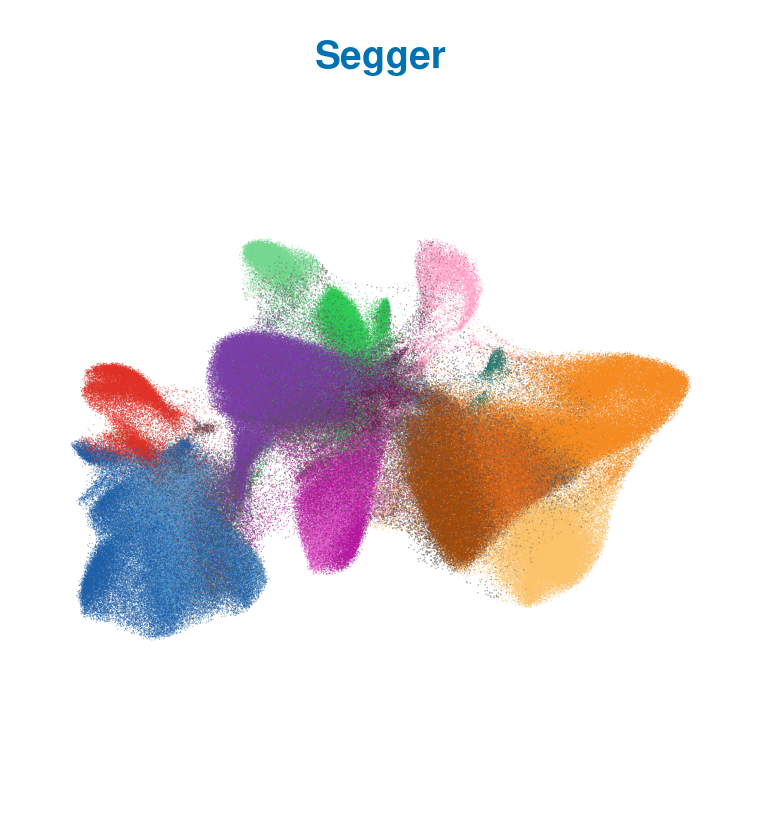

In [9]:
_ = plot_umap("Segger")

### c. The section

Every paired cell at its 10x centroid, coloured by its Segger cell type; boxes are the fields of view of d.


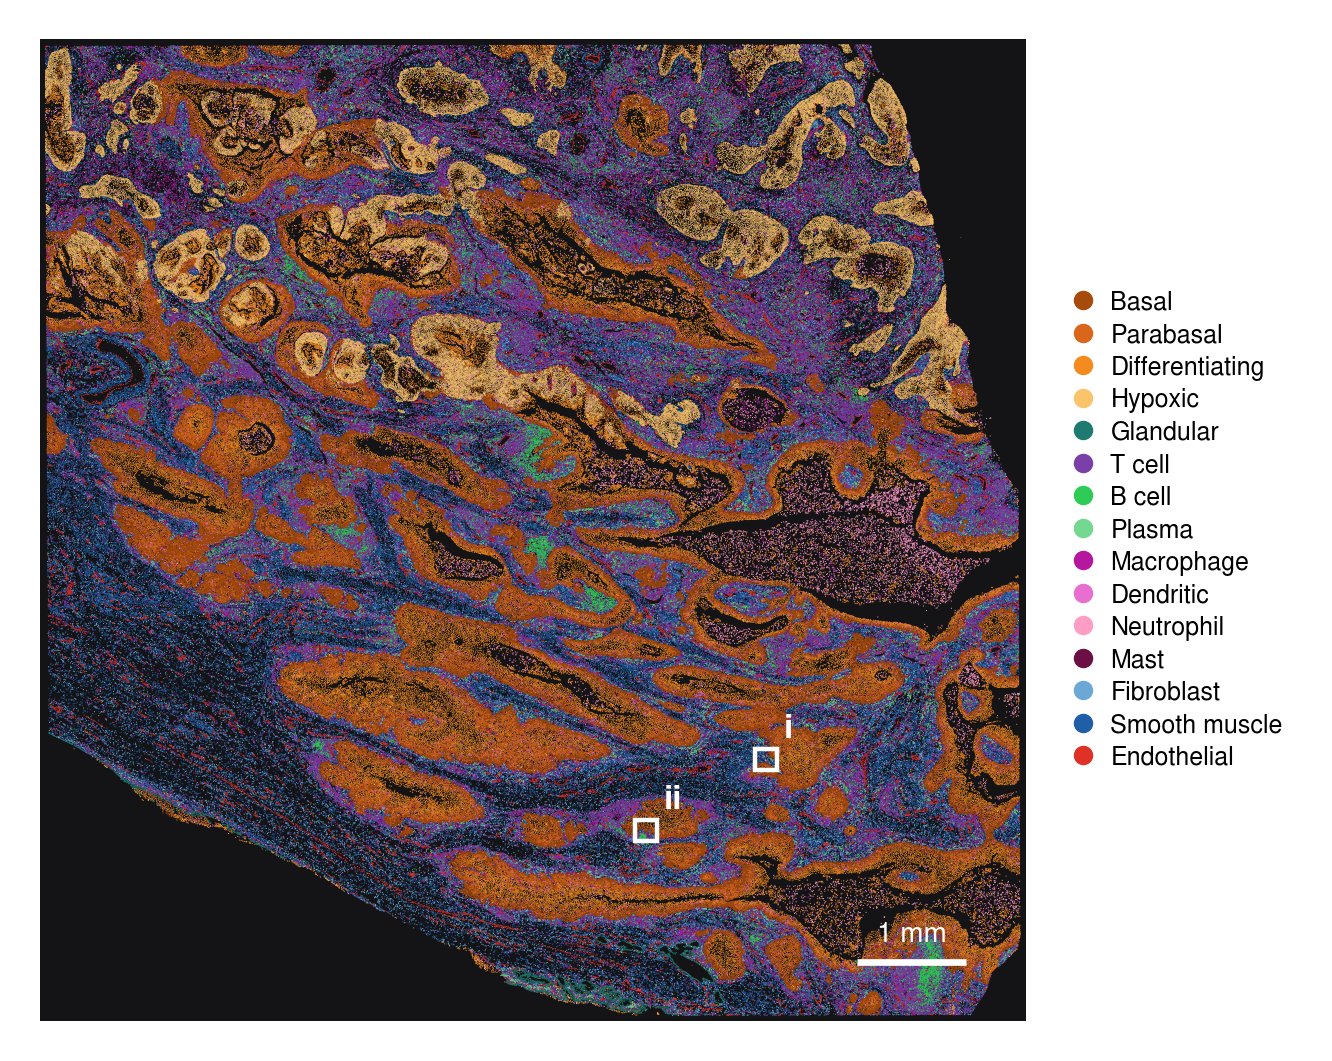

In [10]:
def scale_bar(ax, length, label, x_frac=0.94, y_frac=0.06, color="white"):
    """Scale bar of `length` µm ending at (x_frac, y_frac) of the axes; the y axis points down."""
    (x0, x1), (y1, y0) = ax.get_xlim(), ax.get_ylim()
    xe, y = x0 + x_frac * (x1 - x0), y1 - y_frac * (y1 - y0)
    ax.plot([xe - length, xe], [y, y], color=color, lw=1.2, solid_capstyle="butt")
    ax.text(xe - length / 2, y - 0.015 * (y1 - y0), label, color=color, ha="center", va="bottom", fontsize=5)


MARGIN_SECTION = 50  # µm around the tissue
x_lim = cells["x"].min() - MARGIN_SECTION, cells["x"].max() + MARGIN_SECTION
y_lim = cells["y"].min() - MARGIN_SECTION, cells["y"].max() + MARGIN_SECTION

fig, ax = plt.subplots(figsize=(3.2, 3.2 * np.ptp(y_lim) / np.ptp(x_lim)))
ax.add_patch(Rectangle((x_lim[0], y_lim[0]), np.ptp(x_lim), np.ptp(y_lim), color=FOV_BACKGROUND, zorder=-1))
order = np.random.default_rng(0).permutation(len(cells))
ax.scatter(cells["x"].to_numpy()[order], cells["y"].to_numpy()[order], s=0.04, linewidths=0, rasterized=True,
           c=cells["type_Segger"].map(TYPE_COLORS).to_numpy()[order])
ax.set_xlim(*x_lim)
ax.set_ylim(y_lim[1], y_lim[0])
ax.set_aspect("equal")
ax.set_axis_off()
for k, fov in fovs.iterrows():
    ax.add_patch(Rectangle((fov.x0, fov.y0), FOV_SIZE, FOV_SIZE, fill=False, ec="white", lw=0.8))
    ax.text(fov.x0 + FOV_SIZE + 60, fov.y0 - 40, k, color="white", fontsize=6, fontweight="bold", va="bottom")
scale_bar(ax, 1000, "1 mm")
types = [t for t in TYPE_COLORS if t != "Unresolved"]
handles = [plt.Line2D([], [], ls="", marker="o", ms=2.5, color=TYPE_COLORS[t], label=t) for t in types]
_ = ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=4.5,
              handletextpad=0.1, labelspacing=0.3)

### d. Two fields of view

(i) The epithelial–stromal interface and (ii) B cells meeting tumour epithelium.

Each field of view with 10x (top) and Segger (bottom): cells coloured by their cell type under that segmentation, dimmed; ambiguous calls in grey with a white outline.
10x cells are drawn with their boundaries, Segger cells as the convex hull of the transcripts they keep.

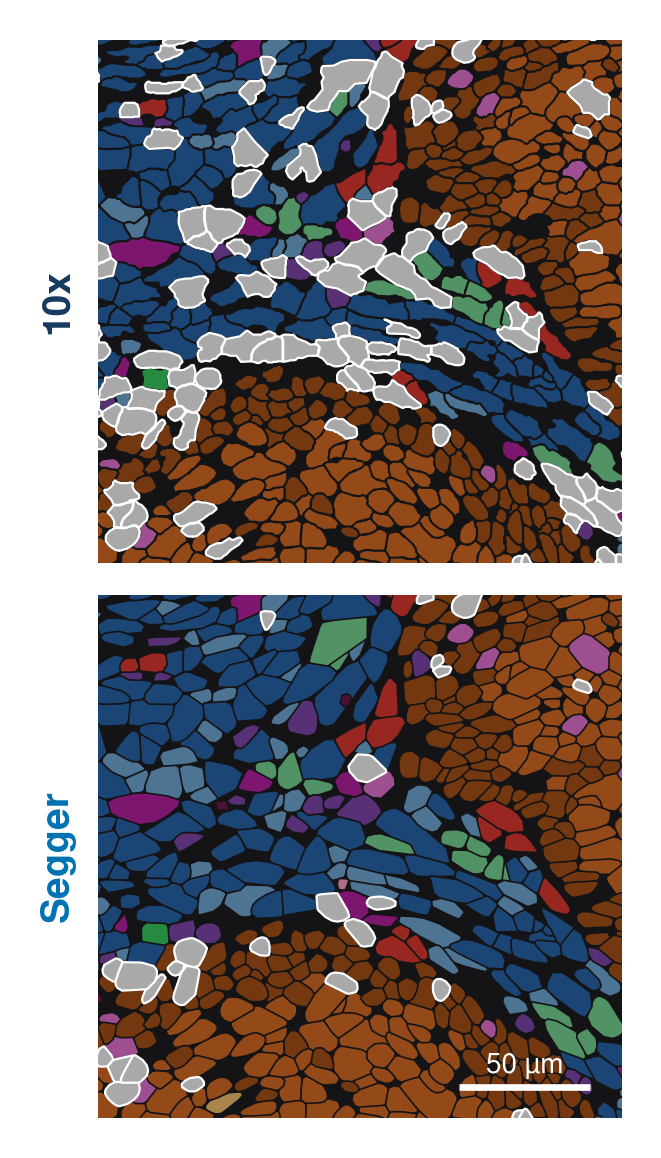

In [11]:
def draw_types(ax, polys, m):
    ids = [c for c in polys if c in cells.index]
    ambiguous = cells.loc[ids, f"ambiguous_{m}"].to_numpy()
    confident = [c for c, a in zip(ids, ambiguous) if not a]
    ax.add_collection(PolyCollection(
        [polys[c] for c in confident], facecolors=[dim(TYPE_COLORS[cells.at[c, f"type_{m}"]], 0.65) for c in confident],
        edgecolors=FOV_BACKGROUND, linewidths=0.3, rasterized=True,
    ))
    ax.add_collection(PolyCollection(
        [polys[c] for c, a in zip(ids, ambiguous) if a], facecolors=AMBIGUOUS_COLOR, edgecolors="white",
        linewidths=0.4, rasterized=True,
    ))


def plot_fov(k):
    fov, (polys, _) = fovs.loc[k], fov_data[k]
    fig, axes = plt.subplots(2, 1, figsize=(1.7, 3.5), gridspec_kw={"hspace": 0.06})
    for ax, m in zip(axes, METHODS):
        dark_tile(ax, fov.x0, fov.y0, FOV_SIZE)
        draw_types(ax, polys[m], m)
        ax.set_ylabel(m, color=METHOD_COLORS[m], fontweight="bold")
    scale_bar(axes[-1], 50, "50 µm")
    return fig


_ = plot_fov("i")

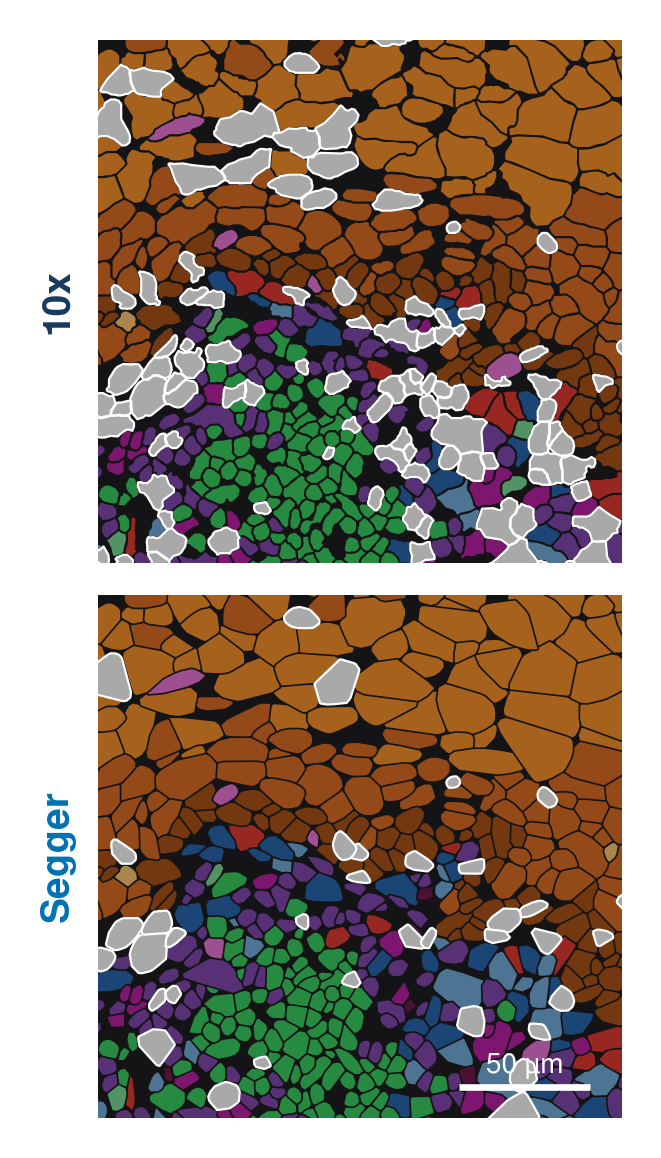

In [12]:
_ = plot_fov("ii")

### Panel helpers

Fixed-size axes, bar and trend plots shared by panels e–h.

In [13]:
BAR_WIDTH, PLOT_WIDTH, PLOT_HEIGHT = 16, 28, 28  # mm, axes of the benchmark panels


def bench_axes(widths, height=PLOT_HEIGHT, left=16, gap=18, right=4, top=6, bottom=13):
    """Figure with axes of fixed size in mm, side by side, so every panel and bar has the same size."""
    fig_width, fig_height = left + sum(widths) + gap * (len(widths) - 1) + right, bottom + height + top
    fig = plt.figure(figsize=(fig_width * MM, fig_height * MM))
    axes, x = [], left
    for w in widths:
        axes.append(fig.add_axes([x / fig_width, bottom / fig_height, w / fig_width, height / fig_height]))
        x += w + gap
    return fig, axes


def decorate(ax, ylabel, arrow):
    """Y label on the axis and an arrow above it for the better direction."""
    if ylabel:
        ax.set_ylabel(ylabel)
    if arrow:
        ax.text(0, 1.03, arrow, transform=ax.transAxes, ha="center", va="bottom", fontsize=7)


def bars(ax, values, low=None, high=None, ylabel=None, arrow=None, reference="10x"):
    """One bar per method with error bars and the reference method as a dashed line (sg_utils.pl.benchmark.bars)."""
    x = np.arange(len(values))
    ax.bar(x, values.to_numpy(), width=0.4, color=[METHOD_COLORS[m] for m in values.index], lw=0)
    if low is not None:
        err = np.clip(np.vstack([values - low, high - values]), 0, None)
        ax.errorbar(x, values, yerr=err, fmt="none", ecolor=INK, elinewidth=0.6, capsize=1.6, capthick=0.6)
    if reference in values.index:
        ax.axhline(values[reference], color=MUTED, lw=0.8, ls=(0, (3, 2)), zorder=0)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_locator(plt.MaxNLocator(3))
    ax.set_xticks(x, values.index)
    ax.tick_params(axis="x", length=0)
    ax.spines["bottom"].set_visible(False)
    ax.set_xlim(-0.6, len(values) - 0.4)
    decorate(ax, ylabel, arrow)


def plot_trend(ax, curves, keys, x_scale=1):
    """Decile points with the interquartile range across tissue squares, joined by a faint line."""
    for m, key in zip(METHODS, keys):
        c = curves[key]
        mean = 100 * c["mean"]
        ax.plot(x_scale * c["x"], mean, "-", lw=0.6, alpha=0.5, color=METHOD_COLORS[m])
        ax.vlines(x_scale * c["x"], 100 * c["q25"], 100 * c["q75"], lw=0.6, color=METHOD_COLORS[m])
        ax.plot(x_scale * c["x"], mean, "o", ms=2, color=METHOD_COLORS[m], label=m)
    ax.set_ylim(0)
    ax.yaxis.set_major_locator(plt.MaxNLocator(4))


def pooled_share(own, foreign):
    return np.nansum(foreign) / (np.nansum(own) + np.nansum(foreign))

### e. Ambiguous calls per cell type

Percentage of the paired cells of each type called ambiguous, each segmentation by its own labels.


,10x,Segger
Mast,61.9,13.4
Dendritic,33.3,21.9
Neutrophil,33.1,4.9
Fibroblast,29.9,4.6
Smooth muscle,28.7,7.4
Macrophage,27.5,10.1
B cell,24.8,9.9
T cell,24.2,9.6
Parabasal,17.6,11.0
Basal,15.2,9.6


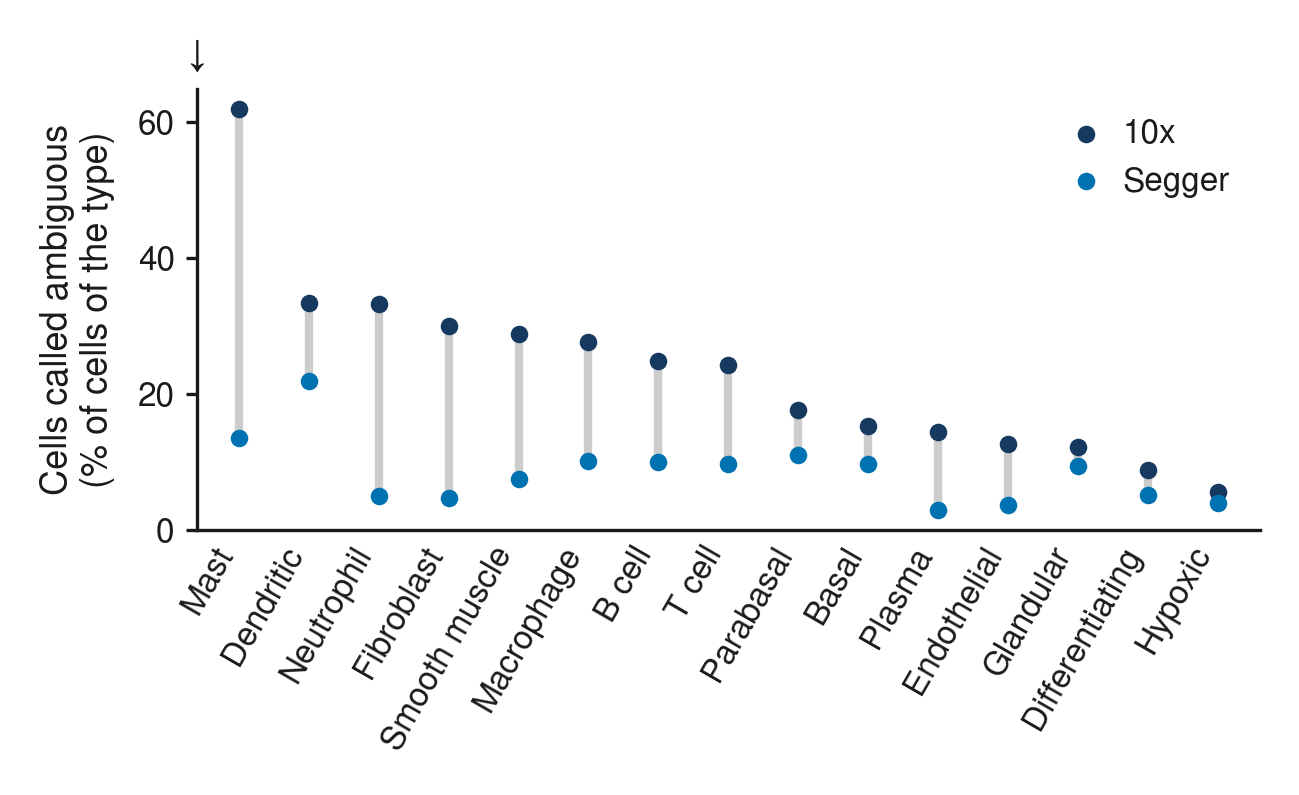

In [14]:
type_rates = pd.DataFrame({
    m: cells.groupby(f"type_{m}")[f"ambiguous_{m}"].mean() * 100 for m in METHODS
}).drop("Unresolved", errors="ignore").sort_values("10x", ascending=False)

with plt.rc_context(BENCH_STYLE):
    fig, (ax,) = bench_axes([4.5 * len(type_rates)], bottom=22)
    x = np.arange(len(type_rates))
    ax.vlines(x, type_rates["Segger"], type_rates["10x"], color="#cccccc", lw=1.5, zorder=1)
    for m in METHODS:
        ax.scatter(x, type_rates[m], s=10, color=METHOD_COLORS[m], label=m, zorder=2, linewidths=0)
    ax.set_xticks(x, type_rates.index, rotation=60, ha="right")
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.6, len(type_rates) - 0.4)
    ax.set_ylim(0)
    ax.yaxis.set_major_locator(plt.MaxNLocator(4))
    decorate(ax, "Cells called ambiguous\n(% of cells of the type)", "↓")
    _ = ax.legend(frameon=False, handletextpad=0.1, loc="upper right")
type_rates.round(1)


### f. Ambiguity against neighbour-label entropy

Cells in deciles of neighbour-label entropy (fewer where values tie); points at the decile's mean x; vertical lines span the 25th to 75th percentile of the decile's value across 500 µm squares of the tissue (squares with at least 30 of the decile's cells).
From the most homogeneous to the most diverse neighbourhoods, the share of 10x calls that are ambiguous triples; Segger's stays low.

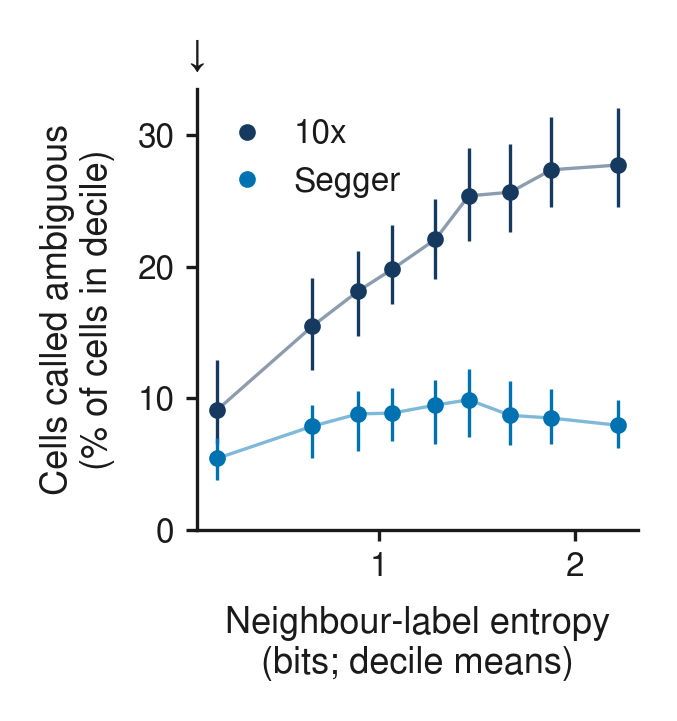

In [15]:
with plt.rc_context(BENCH_STYLE):
    fig, (ax,) = bench_axes([PLOT_WIDTH])
    plot_trend(ax, curves_entropy, [f"ambiguous_{m}" for m in METHODS])
    ax.set_xlabel("Neighbour-label entropy\n(bits; decile means)")
    decorate(ax, "Cells called ambiguous\n(% of cells in decile)", "↓")
    _ = ax.legend(frameon=False, handlelength=1.2, loc="upper left")

### g. Ambiguity against contamination removed by Segger

Cells in deciles of the share of their 10x transcripts that Segger removes; points at the decile's mean x; vertical lines span the 25th to 75th percentile of the decile's value across 500 µm squares of the tissue (squares with at least 30 of the decile's cells).
The more Segger removes from a 10x cell, the likelier 10x is to call it ambiguous; the same cells typed with Segger's transcripts are confident.

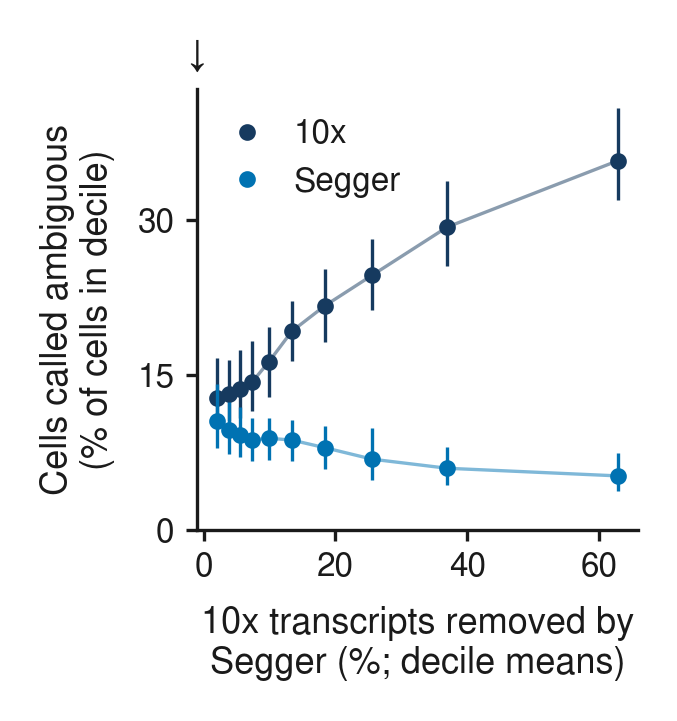

In [16]:
with plt.rc_context(BENCH_STYLE):
    fig, (ax,) = bench_axes([PLOT_WIDTH])
    plot_trend(ax, curves_removed, [f"ambiguous_{m}" for m in METHODS], x_scale=100)
    ax.set_xlabel("10x transcripts removed by\nSegger (%; decile means)")
    decorate(ax, "Cells called ambiguous\n(% of cells in decile)", "↓")
    _ = ax.legend(frameon=False, handlelength=1.2, loc="upper left")

### h. Transcripts and lineage markers per cell

Left ("Transcripts / cell"): median over the paired cells, with the interquartile range over cells; the dashed line marks 10x.
Center ("Own-lineage markers / cell"): in-lineage marker transcripts per cell (mean over the paired cells), each segmentation scored by its own annotation; the dashed line marks 10x.
Right ("Foreign-lineage markers"): foreign share, pooled over the paired cells, each segmentation scored by its own annotation; the dashed line is the same share in the reference cells, which were never segmented.
In the center and right, error bars are the interquartile range across 500 µm squares of the tissue with at least 50 cells.


transcripts / cell, median [IQR]: {'10x': [579, 993, 1771], 'Segger': [449, 865, 1666]}
reference foreign share 5.0%; Segger removes 89% of the excess over it


,10x foreign (%),Segger foreign (%),reference foreign (%),10x own / cell,Segger own / cell
Epithelial,3.7,2.3,2.7,141.6,143.2
Lymphoid,48.1,32.4,14.4,11.4,11.3
Myeloid,54.0,32.7,12.9,22.8,20.8
Stromal,13.2,6.1,8.2,37.2,35.2
all cells,11.4,5.8,5.0,72.4,72.3


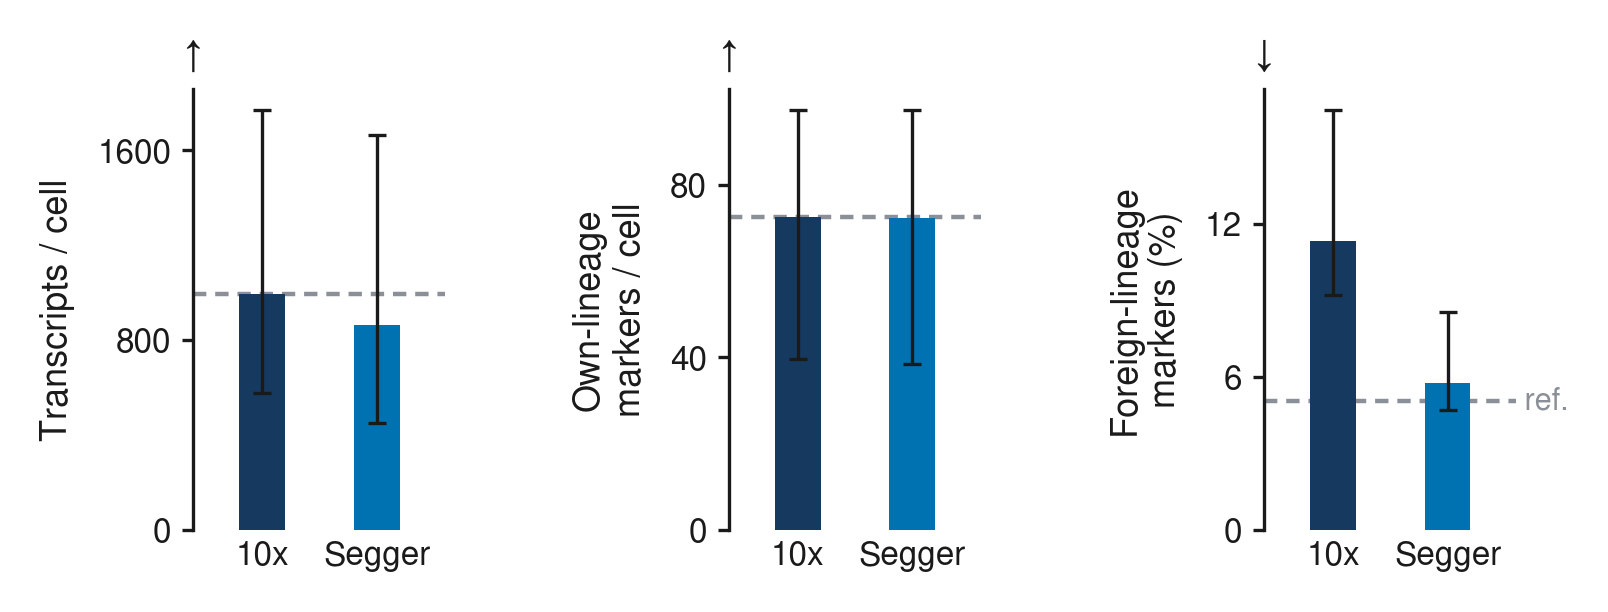

In [17]:
squares = cells.groupby("block").size()
by_square = cells[cells["block"].isin(squares[squares >= 50].index)].groupby("block")
summary_h = {}
for m in METHODS:
    sums = by_square[[f"own_markers_{m}", f"foreign_markers_{m}"]].sum()
    share_sq = 100 * sums.iloc[:, 1] / sums.sum(axis=1)
    own_sq = by_square[f"own_markers_{m}"].mean()
    summary_h[m] = {
        "share": 100 * pooled_share(cells[f"own_markers_{m}"], cells[f"foreign_markers_{m}"]),
        "share_q1": share_sq.quantile(0.25), "share_q3": share_sq.quantile(0.75),
        "own": cells[f"own_markers_{m}"].mean(), "own_q1": own_sq.quantile(0.25), "own_q3": own_sq.quantile(0.75),
    }
summary_h = pd.DataFrame(summary_h).T
reference_share = 100 * pooled_share(ref_own, ref_foreign)
summary_h["excess over reference"] = summary_h["share"] - reference_share

with plt.rc_context(BENCH_STYLE):
    fig, axes = bench_axes([BAR_WIDTH, BAR_WIDTH, BAR_WIDTH])
    q = pd.DataFrame({m: np.percentile(cells[f"n_{m}"], [25, 50, 75]) for m in METHODS}, index=["q1", "q2", "q3"]).T
    bars(axes[0], q["q2"], q["q1"], q["q3"], ylabel="Transcripts / cell", arrow="↑")
    bars(axes[1], summary_h["own"], summary_h["own_q1"], summary_h["own_q3"], ylabel="Own-lineage\nmarkers / cell", arrow="↑")
    bars(axes[2], summary_h["share"], summary_h["share_q1"], summary_h["share_q3"],
         ylabel="Foreign-lineage\nmarkers (%)", arrow="↓", reference=None)
    axes[2].axhline(reference_share, color=MUTED, lw=0.8, ls=(0, (3, 2)), zorder=0)
    axes[2].text(1.0, reference_share, " ref.", transform=axes[2].get_yaxis_transform(), color=MUTED, va="center",
                 fontsize=5.5)

print("transcripts / cell, median [IQR]:", {m: q.loc[m].round().astype(int).tolist() for m in METHODS})
removed = 1 - summary_h.at["Segger", "excess over reference"] / summary_h.at["10x", "excess over reference"]
print(f"reference foreign share {reference_share:.1f}%; Segger removes {100 * removed:.0f}% of the excess over it")
by_lineage = pd.DataFrame({
    **{f"{m} foreign (%)": cells.groupby(cells[f"type_{m}"].map(LINEAGE)).apply(
        lambda d: 100 * pooled_share(d[f"own_markers_{m}"], d[f"foreign_markers_{m}"])) for m in METHODS},
    "reference foreign (%)": 100 * pd.Series(ref_foreign, index=ref.obs["lineage"]).groupby(level=0).sum()
                             / pd.Series(ref_own + ref_foreign, index=ref.obs["lineage"]).groupby(level=0).sum(),
    **{f"{m} own / cell": cells.groupby(cells[f"type_{m}"].map(LINEAGE))[f"own_markers_{m}"].mean() for m in METHODS},
})
by_lineage.loc["all cells"] = list(summary_h["share"]) + [reference_share] + list(summary_h["own"])
by_lineage.round(1)